# VYNDRA — Results Dashboard and Viva Notes

This notebook **reads the saved evaluation outputs** in `results/` and summarises them. It does not retrain
models, rescan image datasets or invent missing numbers. If an output is missing, the cell tells you which
script to run (see the *Reproducing everything from scratch* section of the project `README.md`).

It works whether Jupyter is started from the repository root or from `notebooks/`.

**Read this first:** the synthetic chat and social data are reproducible *test material*, not real user
behaviour. Vision scores depend on the reviewed class maps and on test images the model may have seen
during training, so they are not a guarantee of real-world accuracy.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.image import imread

ROOT = Path.cwd()
if not (ROOT / "data/raw/Db.csv").exists():  # Jupyter started inside notebooks/
    ROOT = ROOT.parent
TABLES, FIGURES = ROOT / "results/tables", ROOT / "results/figures"
print("Repository root:", ROOT)
print("Results folder found:", TABLES.exists())

def load_json(relative_path):
    path = TABLES / relative_path
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else None

Repository root: /Volumes/SANDISK/VYNDRA-backend
Results folder found: True


## 1. Inventory of saved result files
The folder names `part4`–`part7` are project-module labels (not versions): `part4` text/chat analytics,
`part5` social network analytics, `part6` food clustering, `part7` vision evaluation.

In [2]:
MODULES = {"part4": "Text / chat analytics", "part5": "Social network analytics",
           "part6": "Food clustering", "part7": "Vision evaluation"}
inventory = []
for folder, label in MODULES.items():
    tables = [p for p in (TABLES / folder).glob("*") if p.is_file()]
    figures = list((FIGURES / folder).glob("*.png"))
    inventory.append({"folder": folder, "module": label, "table files (csv/json)": len(tables), "figures (png)": len(figures)})
print(pd.DataFrame(inventory).to_string(index=False))

folder                   module  table files (csv/json)  figures (png)
 part4    Text / chat analytics                      29              1
 part5 Social network analytics                       3              1
 part6          Food clustering                       6              2
 part7        Vision evaluation                       6              2


## 2. Headline metrics (read from saved files)
Each row states **what was measured** so that optimistic numbers (synthetic data) are never mistaken for
realistic ones.

In [3]:
rows = []
text = load_json("part4/text_comparison_summary.json")
if text:
    best = text["best_model"]
    rows.append(("Text", "Best of 12 classifiers, synthetic test split (optimistic: template data)",
                 f"{best['model']} + {best['vectorizer']}: accuracy {best['accuracy']:.3f}, macro-F1 {best['macro_f1']:.3f}"))
review = load_json("part4/review_set_intent_metrics.json")
if review:
    rows.append(("Text", f"Saved intent model on {review['rows']} hand-written messages (realistic)",
                 f"accuracy {review['accuracy']:.3f}, macro-F1 {review['macro_f1']:.3f}"))
vader = load_json("part4/sentiment_vader_metrics.json")
if vader:
    rows.append(("Text", f"VADER sentiment on {vader['rows']} synthetic messages (heuristic labels)",
                 f"macro-F1 {vader['macro_f1']:.3f}"))
mention = load_json("part4/mention_metrics_review.json")
if mention:
    rows.append(("Text", f"Food-mention extraction on {mention['rows']} review messages",
                 f"precision {mention['precision']:.3f}, recall {mention['recall']:.3f}, F1 {mention['f1']:.3f}"))
social = load_json("part5/social_metrics.json")
if social:
    rows.append(("Social", f"Louvain communities, {social['users']} users / {social['events']} synthetic events",
                 f"modularity {social['modularity']:.3f}, ARI vs planted {social['adjusted_rand_index_vs_planted']:.2f}"))
clusters = load_json("part6/food_cluster_descriptions.json")
kmeans = TABLES / "part6/food_kmeans_metrics.csv"
if clusters and kmeans.exists():
    k = clusters["selected_k"]
    silhouette = pd.read_csv(kmeans).query("k == @k")["silhouette"].iloc[0]
    rows.append(("Clustering", "K-Means on scaled macronutrients, k chosen by silhouette",
                 f"k = {k}, silhouette {silhouette:.3f}"))
vision = load_json("part7/vision_evaluation_summary.json")
if vision:
    rows.append(("Vision", f"YOLO best.pt on {vision['manifest_rows']} reviewed external images",
                 f"top-1 {vision['top1_accuracy_accepted_classes']:.3f}, top-3 {vision['top3_accuracy_accepted_classes']:.3f}"))
if rows:
    print(pd.DataFrame(rows, columns=["Module", "What was measured", "Result"]).to_string(index=False))
else:
    print("No saved results found. Follow the pipeline in README.md first.")

    Module                                                        What was measured                                                   Result
      Text Best of 12 classifiers, synthetic test split (optimistic: template data) MultinomialNB + bow_word: accuracy 1.000, macro-F1 1.000
      Text              Saved intent model on 150 hand-written messages (realistic)                           accuracy 0.707, macro-F1 0.697
      Text             VADER sentiment on 500 synthetic messages (heuristic labels)                                           macro-F1 0.494
      Text                           Food-mention extraction on 150 review messages                  precision 0.690, recall 0.808, F1 0.744
    Social                    Louvain communities, 60 users / 1800 synthetic events                    modularity 0.502, ARI vs planted 1.00
Clustering                 K-Means on scaled macronutrients, k chosen by silhouette                                  k = 2, silhouette 0.490
    Vision   

## 3. Vision: by dataset and against the classical baselines
The HSV-histogram baselines (Gaussian NB, Decision Tree, k-NN) show how much of the task a colour-only
method can solve. **Observation vs inference:** the table below is observation; the claim that YOLO learned
shape/texture features beyond colour is an inference. The baselines use a different test split than YOLO,
so the comparison is indicative only.

In [4]:
for name in ["part7/vision_metrics_by_dataset.csv", "part7/vision_model_comparison.csv"]:
    path = TABLES / name
    print(f"\n{name}")
    print(pd.read_csv(path).round(3).to_string(index=False) if path.exists()
          else "  missing: run scripts/evaluate_vision_suite.py")


part7/vision_metrics_by_dataset.csv
           dataset  images  top1_accuracy_accepted  top3_accuracy_accepted  top1_accuracy_primary
indian_food_images     240                   0.338                   0.625                  0.338
             khana     450                   0.287                   0.436                  0.253

part7/vision_model_comparison.csv
          method  top1_accuracy  macro_precision_supported  macro_recall_supported  macro_f1_supported
    YOLO_best.pt          0.304                      0.720                   0.272               0.360
  HSV_GaussianNB          0.149                      0.193                   0.149               0.139
HSV_DecisionTree          0.261                      0.269                   0.261               0.262
         HSV_kNN          0.200                      0.231                   0.200               0.196


## 4. Saved figures

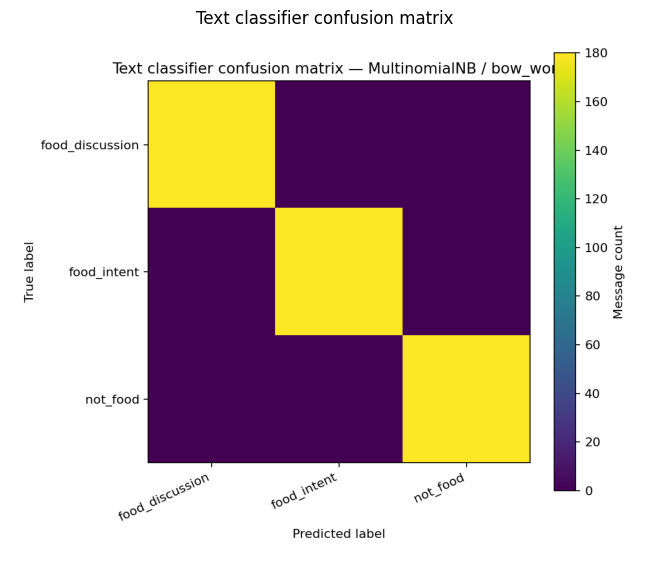

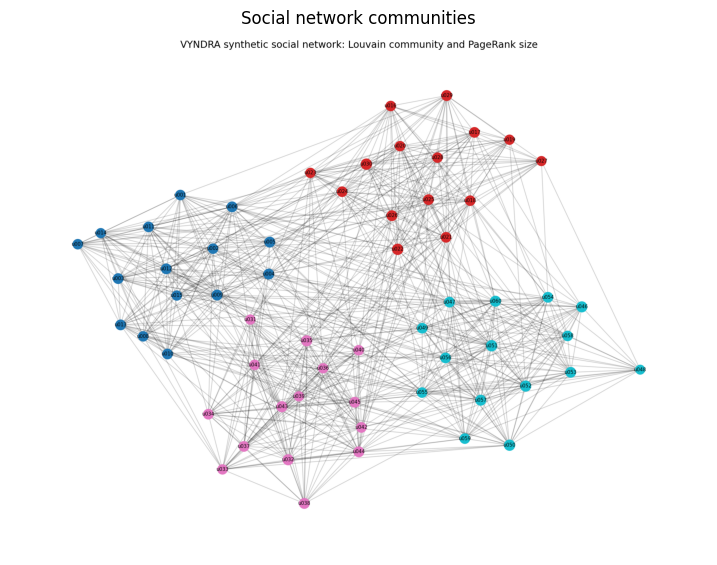

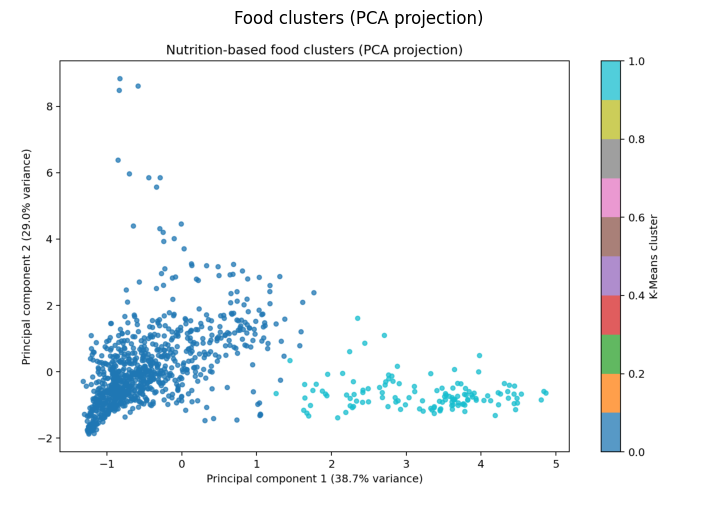

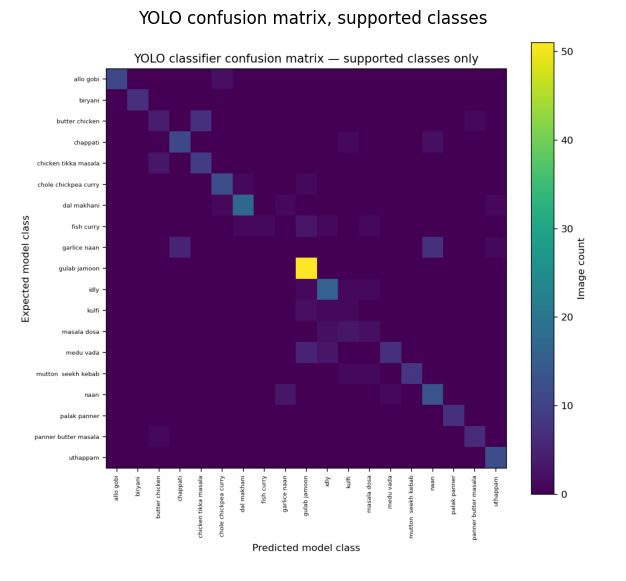

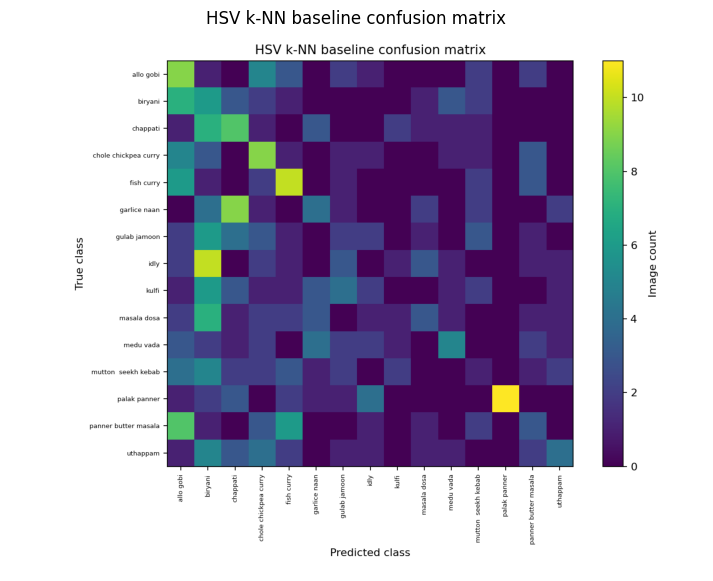

In [5]:
FIGURE_LIST = [("part4/text_confusion_matrix.png", "Text classifier confusion matrix"),
               ("part5/social_network_communities.png", "Social network communities"),
               ("part6/food_clusters_pca.png", "Food clusters (PCA projection)"),
               ("part7/vision_confusion_supported.png", "YOLO confusion matrix, supported classes"),
               ("part7/vision_baseline_confusion.png", "HSV k-NN baseline confusion matrix")]
for relative_path, title in FIGURE_LIST:
    path = FIGURES / relative_path
    if not path.exists():
        print("missing:", relative_path)
        continue
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(imread(path))
    ax.set_title(title)
    ax.axis("off")
    plt.show()

## 5. Viva notes

- **SQLite:** a local relational database persists users, meals, meal items, messages and reactions. Foreign
  keys connect each meal to its items; parameterised SQL avoids concatenating user values into statements.
- **Validation:** endpoints check content type, field types, lengths, quantity bounds (0–5000 g), list sizes
  and unknown foods. Unknown nutrition is never guessed.
- **Privacy:** `/api/chat/send` stores message text so a conversation can be shown. `/api/chat/analyze`
  stores only derived labels, text length and a SHA-256 digest (a digest is not anonymisation). Uploaded
  images are deleted after processing unless `keep=true`. There is no authentication.
- **Chat models:** the intent classifier is trained on synthetic template messages; its high synthetic score is
  optimistic. The hand-written review set is the realistic check.
- **Vision:** a YOLO11n-cls model with 220 dish classes. Only reviewed `exact`/`family` class-to-nutrition
  mappings return nutrition. Metrics on external datasets are far below the training validation score, which
  is itself a finding about domain shift and unknown training-data provenance.
- **Social analytics:** users and events are synthetic with planted communities, so recovering them (ARI = 1.0)
  demonstrates the method, not real-world influence.
- **Clustering:** K-Means and Ward on per-100 g macronutrients; diet/mood tags are rule-generated.
- **Limitations:** dish recognition gives a likely label, not portion size; nutrition varies by recipe.

## 6. Final release checklist

1. `python -m pytest -q` passes and the output is saved.
2. `python scripts/acceptance_check.py --all` passes.
3. The API smoke tests in `README.md` work while `python app.py` is running.
4. No personal images, `.env`, `*.sqlite3` files, downloaded datasets or unreviewed uploads are committed.
5. Limitations are stated honestly in the report and the viva.
6. Do not call the backend production-ready until authentication, authorisation, rate limiting and a data
   retention policy exist.